# Telco Customer Churn Prediction: End-to-End, Leakage-Safe ML Pipeline

Predict which telecom customers are likely to churn, compare models fairly, and translate model performance into **business value**.


## 1. Setup

In [87]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
    accuracy_score, average_precision_score, classification_report, f1_score,
    make_scorer, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, StratifiedKFold,
    cross_val_predict, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from IPython.display import display
except ImportError:  # allows running as a plain script
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_FOLDS = 5
RF_SEARCH_ITER = 40          # random-search budget for Random Forest
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Load data

In [89]:
df_raw = pd.read_csv("../data/telco_customer_churn.csv")
df_raw.head()
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 3. Data cleaning

Only **non-statistical** cleaning happens here (type fixes, dropping the ID, encoding the target).
Anything that learns from the data, such as median imputation, scaling and one-hot encoding, is deferred to the pipeline so it is fitted on training data only.

In [91]:
df = df_raw.drop(columns=["customerID"]).copy()

# TotalCharges is stored as text; blanks (new customers with tenure = 0) become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
n_blank = int(df["TotalCharges"].isna().sum())
print(f"TotalCharges blanks converted to NaN: {n_blank} (all have tenure == 0: "
      f"{bool((df.loc[df['TotalCharges'].isna(), 'tenure'] == 0).all())})")

# Binary target
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
assert df["Churn"].notna().all(), "Unexpected Churn labels"

print(f"Exact duplicate rows (reported, not dropped): {int(df.duplicated().sum())}")
print(f"Overall churn rate: {df['Churn'].mean():.1%}")
df.isna().sum()[lambda s: s > 0]

TotalCharges blanks converted to NaN: 11 (all have tenure == 0: True)
Exact duplicate rows (reported, not dropped): 22
Overall churn rate: 26.5%


TotalCharges    11
dtype: int64

## 4. Exploratory data analysis

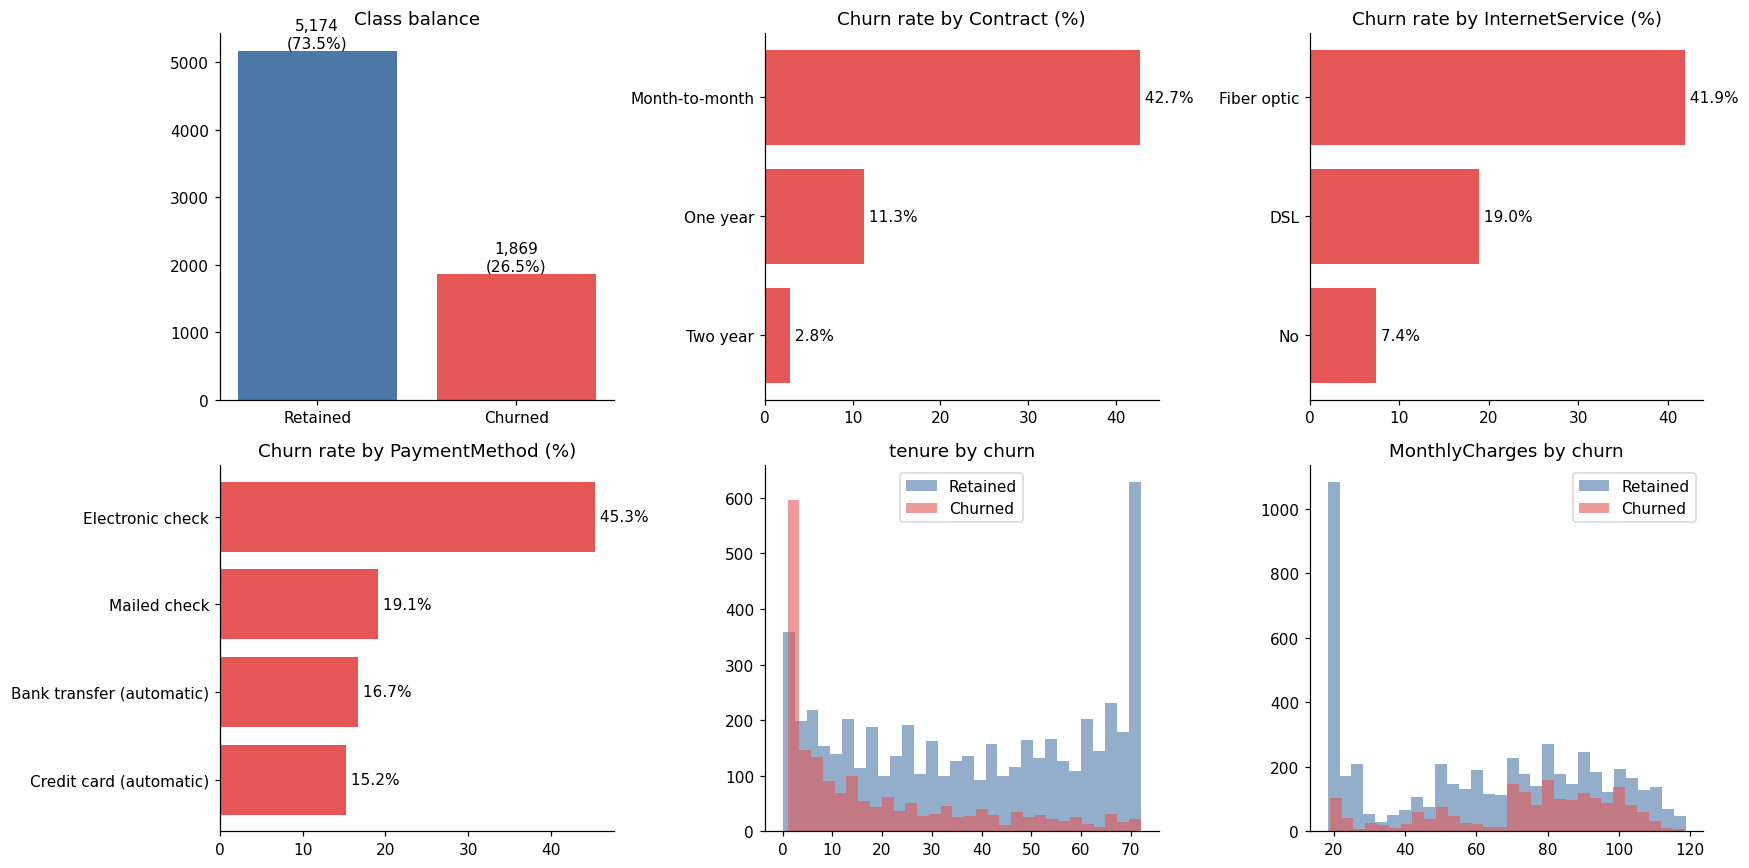

Churn rate by contract type:
Contract
Month-to-month    42.7%
One year          11.3%
Two year           2.8%


In [93]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# churn balance
counts = df["Churn"].value_counts().sort_index()
axes[0, 0].bar(["Retained", "Churned"], counts.values, color=["#4C78A8", "#E45756"])
axes[0, 0].set_title("Class balance")
for i, v in enumerate(counts.values):
    axes[0, 0].text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")

# churn rate by categorical drivers
for ax, col in zip([axes[0, 1], axes[0, 2], axes[1, 0]], ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["Churn"].mean().sort_values()
    ax.barh(rate.index, rate.values * 100, color="#E45756")
    ax.set_title(f"Churn rate by {col} (%)")
    for i, v in enumerate(rate.values):
        ax.text(v * 100, i, f" {v:.1%}", va="center")

# numeric distributions
for ax, col in zip([axes[1, 1], axes[1, 2]], ["tenure", "MonthlyCharges"]):
    for label, colour, name in [(0, "#4C78A8", "Retained"), (1, "#E45756", "Churned")]:
        ax.hist(df.loc[df["Churn"] == label, col], bins=30, alpha=0.6, color=colour, label=name)
    ax.set_title(f"{col} by churn")
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_overview.png", bbox_inches="tight")
plt.show()

top_line = df.groupby("Contract")["Churn"].mean()
print("Churn rate by contract type:")
print(top_line.map("{:.1%}".format).to_string())

## 5. Train/test split and preprocessing pipeline

* **Stratified** 80/20 split preserves the churn ratio.
* Numeric columns → median imputation → standard scaling.
* Categorical columns → one-hot encoding (unknown categories ignored at inference time).

In [95]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]:,} rows | churn rate {y_train.mean():.2%}")
print(f"Test : {X_test.shape[0]:,} rows | churn rate {y_test.mean():.2%}")

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(f"{len(num_cols)} numeric + {len(cat_cols)} categorical features")


def make_pipeline(clf):
    preprocessor = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    return Pipeline([("prep", preprocessor), ("clf", clf)])


cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# how many model inputs after encoding?
n_encoded = make_pipeline(LogisticRegression()).named_steps["prep"].fit(X_train).get_feature_names_out().size
print(f"Features after encoding: {n_encoded}")

Train: 5,634 rows | churn rate 26.54%
Test : 1,409 rows | churn rate 26.54%
4 numeric + 15 categorical features
Features after encoding: 45


## 6. Evaluation helpers

In [97]:
def evaluate(model, X_, y_, threshold=0.5):
    # All scores use predicted probabilities where applicable (ROC-AUC, PR-AUC).
    proba = model.predict_proba(X_)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_, pred),
        "precision": precision_score(y_, pred, zero_division=0),
        "recall": recall_score(y_, pred),
        "f1": f1_score(y_, pred),
        "f1_weighted": f1_score(y_, pred, average="weighted"),
        "roc_auc": roc_auc_score(y_, proba),
        "pr_auc": average_precision_score(y_, proba),
    }


scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
}

## 7. Baseline models (5-fold stratified cross-validation on the training set)

A `DummyClassifier` shows what "no skill" looks like, which is important context for the accuracy numbers.

In [99]:
baselines = {
    "Dummy (majority prior)": DummyClassifier(strategy="prior"),
    "LogReg (default)": LogisticRegression(max_iter=2000),
    "RandomForest (default)": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

rows = {}
for name, clf in baselines.items():
    res = cross_validate(make_pipeline(clf), X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    rows[name] = {m: res[f"test_{m}"].mean() for m in scoring}
    rows[name]["train_accuracy"] = res["train_accuracy"].mean()

cv_baseline = pd.DataFrame(rows).T
display(cv_baseline.round(4))

,roc_auc,accuracy,precision,recall,f1,train_accuracy
Dummy (majority prior),0.5000,0.7346,0.0000,0.0000,0.0000,0.7346
LogReg (default),0.8461,0.8021,0.6529,0.5431,0.5923,0.8063
RandomForest (default),0.8182,0.7842,0.6215,0.4789,0.5408,0.9983


## 8. Hyperparameter tuning

* Grids only contain **valid** parameter combinations, and `error_score="raise"` makes any bad combination fail loudly rather than silently scoring `NaN`.
* The search **optimises ROC-AUC** (`refit="roc_auc"`) while tracking F1, recall, precision and accuracy.
* `class_weight` is tuned so the search can trade off precision against recall on the minority (churn) class.
* Random Forest uses randomized search for a bigger space at lower cost; Logistic Regression is small enough for an exhaustive grid.

In [101]:
lr_grid = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "clf__class_weight": [None, "balanced"],
}

rf_space = {
    "clf__n_estimators": [200, 300, 500],
    "clf__max_depth": [5, 8, 10, 15, None],
    "clf__min_samples_split": [2, 8, 15, 20],
    "clf__min_samples_leaf": [1, 3, 5],
    "clf__max_features": ["sqrt", "log2", 0.3, 0.5],
    "clf__class_weight": [None, "balanced_subsample"],
}

lr_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    lr_grid, scoring=scoring, refit="roc_auc", cv=cv, n_jobs=-1,
    error_score="raise", return_train_score=True,
)
rf_search = RandomizedSearchCV(
    make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    rf_space, n_iter=RF_SEARCH_ITER, scoring=scoring, refit="roc_auc", cv=cv, n_jobs=-1,
    error_score="raise", return_train_score=True, random_state=RANDOM_STATE,
)

lr_search.fit(X_train, y_train)
rf_search.fit(X_train, y_train)

total_configs = total_fits = 0
for name, search in [("Logistic Regression", lr_search), ("Random Forest", rf_search)]:
    r = pd.DataFrame(search.cv_results_)
    n_cfg, failed = len(r), int(r["mean_test_roc_auc"].isna().sum())
    total_configs += n_cfg
    total_fits += n_cfg * N_FOLDS
    print(f"{name}: {n_cfg} configurations x {N_FOLDS} folds = {n_cfg * N_FOLDS} fits | failed: {failed}")
    print(f"  best CV ROC-AUC = {search.best_score_:.4f}")
    print(f"  best params     = { {k.replace('clf__', ''): v for k, v in search.best_params_.items()} }")

print(f"\nTotal: {total_configs} configurations, {total_fits} cross-validated fits, 0 failures expected")

Logistic Regression: 12 configurations x 5 folds = 60 fits | failed: 0
  best CV ROC-AUC = 0.8463
  best params     = {'C': 10, 'class_weight': None}
Random Forest: 40 configurations x 5 folds = 200 fits | failed: 0
  best CV ROC-AUC = 0.8480
  best params     = {'n_estimators': 200, 'min_samples_split': 15, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8, 'class_weight': 'balanced_subsample'}

Total: 52 configurations, 260 cross-validated fits, 0 failures expected


## 9. Overfitting analysis: default vs tuned

The final tuned models are the search's `best_estimator_`, refit on the full training set, so what is reported is exactly what was tuned.

In [103]:
models = {
    "LogReg (default)": make_pipeline(LogisticRegression(max_iter=2000)).fit(X_train, y_train),
    "LogReg (tuned)": lr_search.best_estimator_,
    "RandomForest (default)": make_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)).fit(X_train, y_train),
    "RandomForest (tuned)": rf_search.best_estimator_,
}

gap_rows = {}
for name, m in models.items():
    tr, te = evaluate(m, X_train, y_train), evaluate(m, X_test, y_test)
    gap_rows[name] = {
        "train_acc": tr["accuracy"], "test_acc": te["accuracy"],
        "acc_gap_pts": (tr["accuracy"] - te["accuracy"]) * 100,
        "train_auc": tr["roc_auc"], "test_auc": te["roc_auc"],
        "auc_gap": tr["roc_auc"] - te["roc_auc"],
    }
gap_df = pd.DataFrame(gap_rows).T
display(gap_df.round(4))

rf_before, rf_after = gap_df.loc["RandomForest (default)"], gap_df.loc["RandomForest (tuned)"]
print(f"Random Forest train-test accuracy gap: {rf_before['acc_gap_pts']:.1f} pts -> {rf_after['acc_gap_pts']:.1f} pts "
      f"(reduction of {rf_before['acc_gap_pts'] - rf_after['acc_gap_pts']:.1f} pts)")
print(f"Random Forest test accuracy: {rf_before['test_acc']:.1%} -> {rf_after['test_acc']:.1%}")
print(f"Random Forest test ROC-AUC : {rf_before['test_auc']:.3f} -> {rf_after['test_auc']:.3f}")

,train_acc,test_acc,acc_gap_pts,train_auc,test_auc,auc_gap
LogReg (default),0.8060,0.8055,0.0463,0.8493,0.8419,0.0074
LogReg (tuned),0.8060,0.8055,0.0463,0.8495,0.8412,0.0084
RandomForest (default),0.9980,0.7764,22.1610,0.9999,0.8162,0.1837
RandomForest (tuned),0.7927,0.7587,3.3993,0.8922,0.8439,0.0483


Random Forest train-test accuracy gap: 22.2 pts -> 3.4 pts (reduction of 18.8 pts)
Random Forest test accuracy: 77.6% -> 75.9%
Random Forest test ROC-AUC : 0.816 -> 0.844


## 10. Held-out test performance (default threshold = 0.50)

ROC-AUC and PR-AUC are computed from predicted probabilities.
`f1` is for the churn class; `f1_weighted` is also shown for comparison with weighted-F1 reporting.

,accuracy,precision,recall,f1,f1_weighted,roc_auc,pr_auc
LogReg (default),0.8055,0.6572,0.5588,0.6040,0.8002,0.8419,0.6334
LogReg (tuned),0.8055,0.6572,0.5588,0.6040,0.8002,0.8412,0.6282
RandomForest (default),0.7764,0.5974,0.4840,0.5347,0.7684,0.8162,0.6057
RandomForest (tuned),0.7587,0.5309,0.7807,0.6320,0.7705,0.8439,0.6544


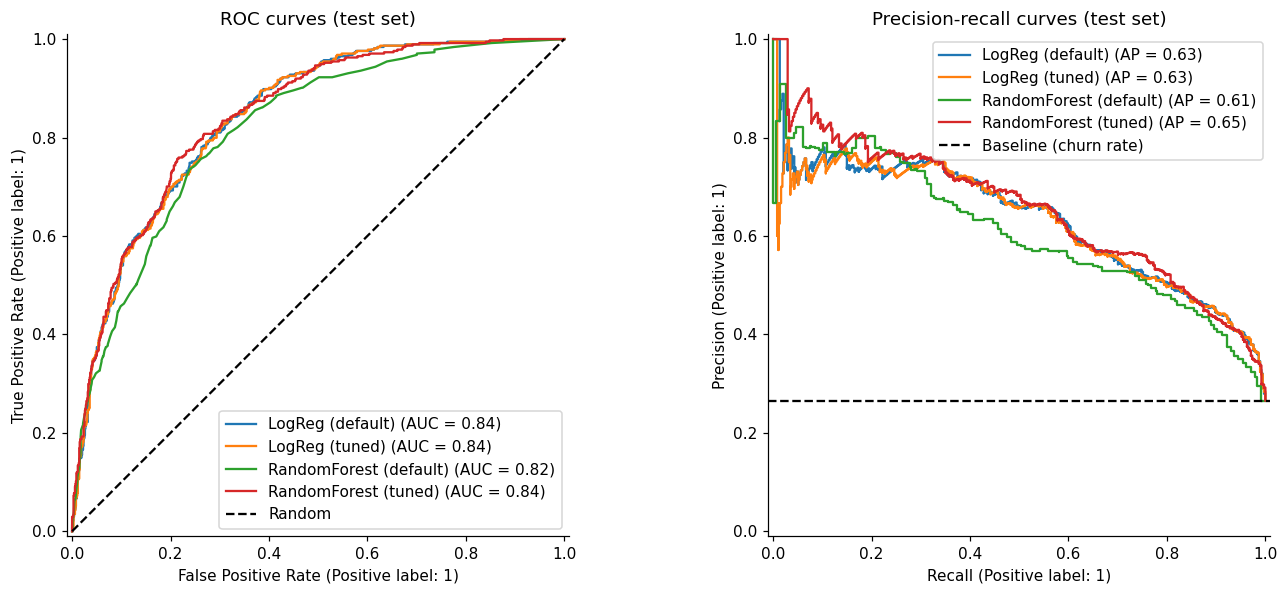

In [105]:
results_df = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
display(results_df.round(4))
results_df.to_csv(OUTPUT_DIR / "test_metrics_threshold_0.50.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=axes[1], name=name)
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_title("ROC curves (test set)")
axes[1].axhline(y_test.mean(), color="k", ls="--", label="Baseline (churn rate)")
axes[1].set_title("Precision-recall curves (test set)")
axes[0].legend(loc="lower right"); axes[1].legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_pr_curves.png", bbox_inches="tight")
plt.show()

## 11. Model selection

The final model is chosen by **cross-validated ROC-AUC on the training data** only, so the test set is never used to pick a model or a threshold.

In [107]:
tuned = {"LogReg (tuned)": lr_search, "RandomForest (tuned)": rf_search}
final_name = max(tuned, key=lambda n: tuned[n].best_score_)
final_model = models[final_name]
print({n: round(s.best_score_, 4) for n, s in tuned.items()})
print(f"Selected model: {final_name}")

{'LogReg (tuned)': 0.8463, 'RandomForest (tuned)': 0.848}
Selected model: RandomForest (tuned)


## 12. Decision threshold chosen for business value

A 0.50 cut-off is rarely optimal for churn: missing a churner (false negative) usually costs more than offering a discount to a customer who would have stayed (false positive).

**Retention-campaign assumptions: edit these to match your business.** They drive every dollar figure in this notebook and are illustrative, not measured from the data.

Avg monthly charge of churners: $74.86 -> value of one saved customer: $898
Value-optimal threshold (OOF): 0.63 | F1-optimal threshold (OOF): 0.52


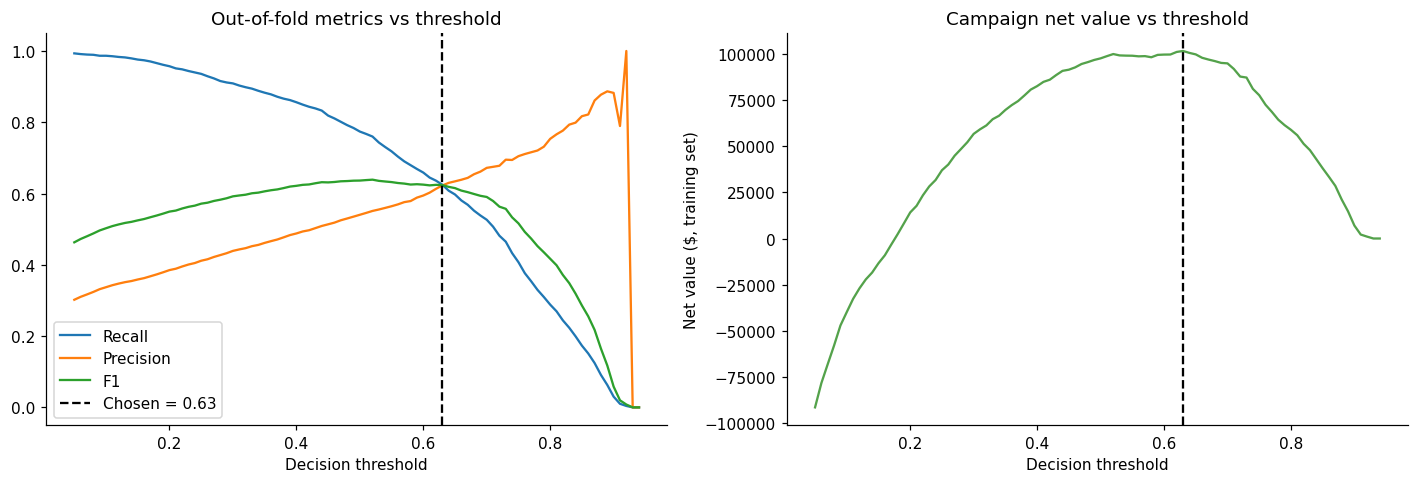

In [109]:
# ---- Business assumptions (EDIT ME) -----------------------------------------
OFFER_COST = 100.0        # cost of the offer + agent time per targeted customer ($)
SAVE_RATE = 0.30          # share of targeted churners the offer actually retains
RETENTION_MONTHS = 12     # months of revenue preserved for each saved customer
# -----------------------------------------------------------------------------

avg_monthly_churner = X_train.loc[y_train == 1, "MonthlyCharges"].mean()
VALUE_PER_SAVED = avg_monthly_churner * RETENTION_MONTHS
print(f"Avg monthly charge of churners: ${avg_monthly_churner:,.2f} -> value of one saved customer: ${VALUE_PER_SAVED:,.0f}")


def net_value(y_true, pred):
    # Net $ benefit vs. running no campaign.
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    tp = int(((pred == 1) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    return tp * (SAVE_RATE * VALUE_PER_SAVED - OFFER_COST) - fp * OFFER_COST


# Out-of-fold probabilities on TRAIN only (no test leakage)
oof_proba = cross_val_predict(clone(final_model), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.round(np.arange(0.05, 0.95, 0.01), 2)
sweep = pd.DataFrame({
    "threshold": thresholds,
    "recall": [recall_score(y_train, oof_proba >= t) for t in thresholds],
    "precision": [precision_score(y_train, oof_proba >= t, zero_division=0) for t in thresholds],
    "f1": [f1_score(y_train, oof_proba >= t) for t in thresholds],
    "net_value": [net_value(y_train, oof_proba >= t) for t in thresholds],
})
THRESHOLD = float(sweep.loc[sweep["net_value"].idxmax(), "threshold"])
f1_threshold = float(sweep.loc[sweep["f1"].idxmax(), "threshold"])
print(f"Value-optimal threshold (OOF): {THRESHOLD:.2f} | F1-optimal threshold (OOF): {f1_threshold:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(sweep["threshold"], sweep["recall"], label="Recall")
axes[0].plot(sweep["threshold"], sweep["precision"], label="Precision")
axes[0].plot(sweep["threshold"], sweep["f1"], label="F1")
axes[0].axvline(THRESHOLD, color="k", ls="--", label=f"Chosen = {THRESHOLD:.2f}")
axes[0].set_xlabel("Decision threshold"); axes[0].set_title("Out-of-fold metrics vs threshold"); axes[0].legend()
axes[1].plot(sweep["threshold"], sweep["net_value"], color="#54A24B")
axes[1].axvline(THRESHOLD, color="k", ls="--")
axes[1].set_xlabel("Decision threshold"); axes[1].set_ylabel("Net value ($, training set)")
axes[1].set_title("Campaign net value vs threshold")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "threshold_tuning.png", bbox_inches="tight")
plt.show()

## 13. Final test evaluation: default threshold vs tuned threshold

,threshold 0.50,threshold 0.63
accuracy,0.7587,0.7842
precision,0.5309,0.5866
recall,0.7807,0.6337
f1,0.6320,0.6093
f1_weighted,0.7705,0.7868
roc_auc,0.8439,0.8439
pr_auc,0.6544,0.6544


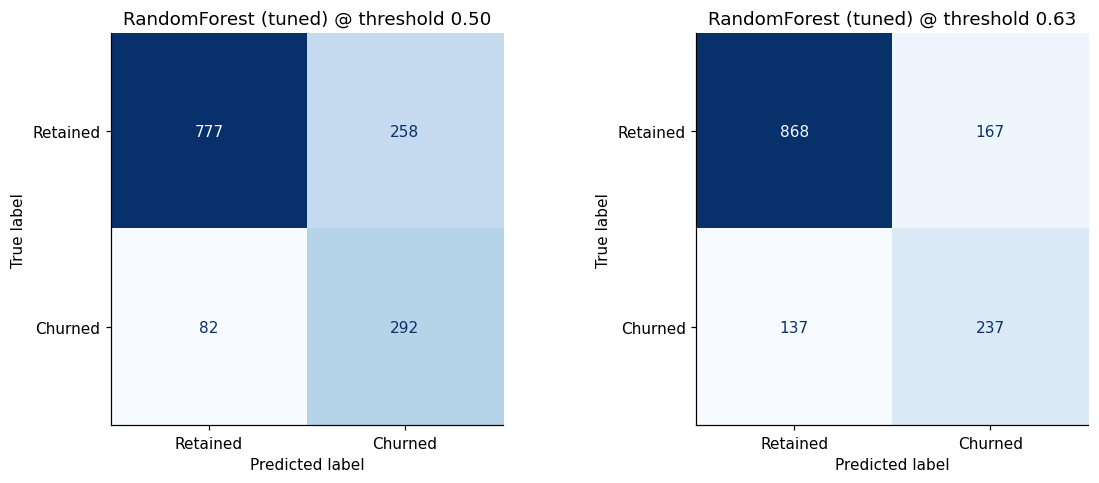

              precision    recall  f1-score   support

    Retained       0.86      0.84      0.85      1035
     Churned       0.59      0.63      0.61       374

    accuracy                           0.78      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409



In [111]:
default_metrics = evaluate(final_model, X_test, y_test, threshold=0.5)
tuned_metrics = evaluate(final_model, X_test, y_test, threshold=THRESHOLD)
compare = pd.DataFrame({"threshold 0.50": default_metrics, f"threshold {THRESHOLD:.2f}": tuned_metrics})
display(compare.round(4))

proba_test = final_model.predict_proba(X_test)[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [0.5, THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (proba_test >= t).astype(int), display_labels=["Retained", "Churned"],
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{final_name} @ threshold {t:.2f}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices.png", bbox_inches="tight")
plt.show()

print(classification_report(y_test, (proba_test >= THRESHOLD).astype(int), target_names=["Retained", "Churned"]))

## 14. Business impact of a retention campaign (test set)

Strategies are compared on the same held-out customers, using the assumptions defined in Section 12.
Figures are **estimates driven by those assumptions**, so state the assumptions whenever you quote them.

In [113]:
y_t = np.asarray(y_test)
strategies = {
    "No campaign": np.zeros(len(y_t), dtype=int),
    "Target every customer": np.ones(len(y_t), dtype=int),
    "Model @ 0.50": (proba_test >= 0.5).astype(int),
    f"Model @ {THRESHOLD:.2f} (tuned)": (proba_test >= THRESHOLD).astype(int),
}

biz_rows = {}
for name, pred in strategies.items():
    nv = net_value(y_t, pred)
    biz_rows[name] = {
        "customers_targeted": int(pred.sum()),
        "churners_reached": int(((pred == 1) & (y_t == 1)).sum()),
        "net_value_usd": nv,
        "net_value_per_1000_customers": nv / len(y_t) * 1000,
    }
biz_df = pd.DataFrame(biz_rows).T
display(biz_df.round(0))
biz_df.to_csv(OUTPUT_DIR / "business_impact.csv")

best_key = f"Model @ {THRESHOLD:.2f} (tuned)"
uplift_vs_all = biz_df.loc[best_key, "net_value_usd"] - biz_df.loc["Target every customer", "net_value_usd"]
def money(v):
    return f"{'+' if v >= 0 else '-'}${abs(v):,.0f}"


print(f"Tuned-model campaign vs. blanket campaign: {money(uplift_vs_all)} on {len(y_t):,} test customers "
      f"({money(biz_df.loc[best_key, 'net_value_per_1000_customers'])} net per 1,000 customers)")

,customers_targeted,churners_reached,net_value_usd,net_value_per_1000_customers
No campaign,0.0,0.0,0.0,0.0
Target every customer,1409.0,374.0,-40108.0,-28466.0
Model @ 0.50,550.0,292.0,23693.0,16815.0
Model @ 0.63 (tuned),404.0,237.0,23471.0,16658.0


Tuned-model campaign vs. blanket campaign: +$63,579 on 1,409 test customers (+$16,658 net per 1,000 customers)


## 15. What drives churn? Permutation feature importance

Computed on the held-out test set with ROC-AUC as the score, directly on the **original** columns (so one-hot dummies do not split a feature's importance).

,feature,importance,std
14,Contract,0.0628,0.0056
4,tenure,0.0260,0.0021
7,InternetService,0.0178,0.0053
18,TotalCharges,0.0123,0.0017
8,OnlineSecurity,0.0065,0.0022
11,TechSupport,0.0046,0.0017
16,PaymentMethod,0.0026,0.0013
15,PaperlessBilling,0.0019,0.0014
13,StreamingMovies,0.0014,0.0010
12,StreamingTV,0.0012,0.0012


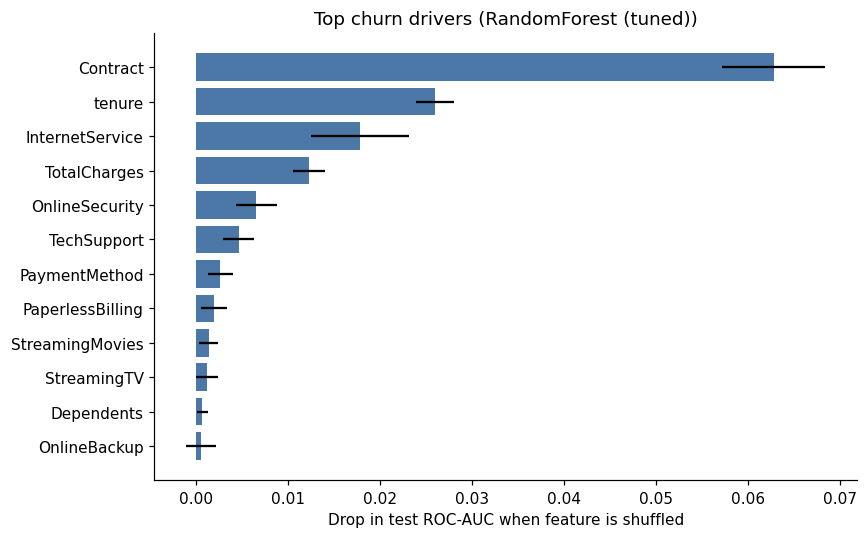

In [115]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
       .sort_values("importance", ascending=False))
display(imp.head(10).round(4))

top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#4C78A8")
plt.xlabel("Drop in test ROC-AUC when feature is shuffled")
plt.title(f"Top churn drivers ({final_name})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", bbox_inches="tight")
plt.show()

## 16. Save artifacts

In [117]:
joblib.dump(final_model, OUTPUT_DIR / "churn_model.joblib")
with open(OUTPUT_DIR / "model_config.json", "w") as f:
    json.dump({
        "model": final_name,
        "decision_threshold": THRESHOLD,
        "best_params": {k.replace("clf__", ""): (v if not isinstance(v, np.generic) else v.item())
                        for k, v in tuned[final_name].best_params_.items()},
        "business_assumptions": {"offer_cost": OFFER_COST, "save_rate": SAVE_RATE,
                                 "retention_months": RETENTION_MONTHS},
        "random_state": RANDOM_STATE,
    }, f, indent=2)
imp.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)
print("Saved:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

# Reload check: the saved model scores new data identically
reloaded = joblib.load(OUTPUT_DIR / "churn_model.joblib")
assert np.allclose(reloaded.predict_proba(X_test)[:, 1], proba_test)
print("Reload check passed")

Saved: ['business_impact.csv', 'churn_model.joblib', 'confusion_matrices.png', 'eda_overview.png', 'feature_importance.csv', 'feature_importance.png', 'model_config.json', 'results_summary.txt', 'roc_pr_curves.png', 'test_metrics_threshold_0.50.csv', 'threshold_tuning.png']
Reload check passed


## 17. Auto-generated results summary

Every number below is computed from this run, so nothing is typed by hand.

In [119]:
top3 = ", ".join(imp.head(3)["feature"])
tm = tuned_metrics
summary = f'''
PROJECT SUMMARY
- Built an end-to-end churn prediction pipeline on {len(df):,} telecom customers ({X.shape[1]} raw features -> {n_encoded} model inputs) using leakage-safe scikit-learn Pipelines, stratified splits and 5-fold stratified cross-validation.
- Tuned Logistic Regression and Random Forest over {total_configs} hyperparameter configurations ({total_fits} cross-validated fits, 0 failed), optimising ROC-AUC with class-imbalance handling.
- Reduced Random Forest overfitting: train-test accuracy gap {rf_before['acc_gap_pts']:.1f} -> {rf_after['acc_gap_pts']:.1f} pts; test ROC-AUC {rf_before['test_auc']:.3f} -> {rf_after['test_auc']:.3f}.
- Selected {final_name} by cross-validated ROC-AUC; on held-out data it achieved ROC-AUC {tm['roc_auc']:.3f}, recall {tm['recall']:.1%}, precision {tm['precision']:.1%} at a tuned decision threshold of {THRESHOLD:.2f} (recall {default_metrics['recall']:.1%} at the default 0.50).
- Estimated retention-campaign net value of {money(biz_df.loc[best_key, 'net_value_per_1000_customers'])} per 1,000 customers ({money(uplift_vs_all)} vs. contacting every customer on the test set), under stated cost assumptions.
- Identified top churn drivers via permutation importance: {top3}.
'''
print(summary)
(OUTPUT_DIR / "results_summary.txt").write_text(summary)


PROJECT SUMMARY
- Built an end-to-end churn prediction pipeline on 7,043 telecom customers (19 raw features -> 45 model inputs) using leakage-safe scikit-learn Pipelines, stratified splits and 5-fold stratified cross-validation.
- Tuned Logistic Regression and Random Forest over 52 hyperparameter configurations (260 cross-validated fits, 0 failed), optimising ROC-AUC with class-imbalance handling.
- Reduced Random Forest overfitting: train-test accuracy gap 22.2 -> 3.4 pts; test ROC-AUC 0.816 -> 0.844.
- Selected RandomForest (tuned) by cross-validated ROC-AUC; on held-out data it achieved ROC-AUC 0.844, recall 63.4%, precision 58.7% at a tuned decision threshold of 0.63 (recall 78.1% at the default 0.50).
- Estimated retention-campaign net value of +$16,658 per 1,000 customers (+$63,579 vs. contacting every customer on the test set), under stated cost assumptions.
- Identified top churn drivers via permutation importance: Contract, tenure, InternetService.



973